In [ ]:
import pandas as pd
df = pd.read_csv("/sales_working.csv")
df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12-06-2017,16-06-2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [ ]:
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)
today = df["Order Date"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Recency=("Order Date", lambda x: (today - x.max()).days),
    Frequency=("Order ID", "nunique"),
    Monetary=("Sales", "sum")
).reset_index()
rfm.head()

,Customer ID,Recency,Frequency,Monetary
0,AA-10315,185,5,5563.560
1,AA-10375,20,9,1056.390
2,AA-10480,260,4,1790.512
3,AA-10645,56,6,5086.935
4,AB-10015,416,3,886.156


In [ ]:
len(rfm)

793

In [ ]:
from sklearn.preprocessing import StandardScaler
X = StandardScaler().fit_transform(rfm[["Recency","Frequency","Monetary"]])

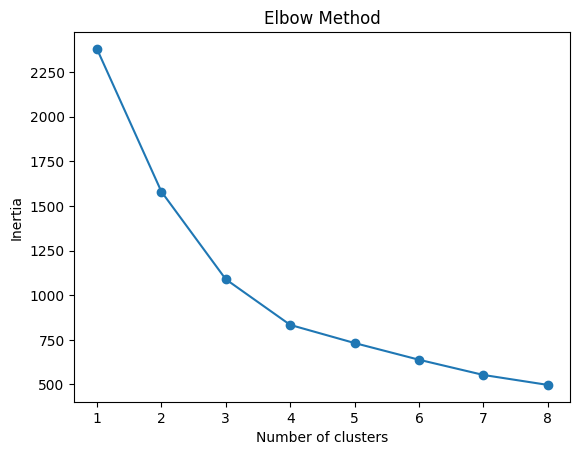

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
for k in range(1, 9):
    inertia.append(KMeans(n_clusters=k, random_state=42, n_init=10).fit(X).inertia_)
plt.plot(range(1, 9), inertia, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [ ]:
km = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Segment"] = km.fit_predict(X)

summary = rfm.groupby("Segment").agg(
    Customers=("Customer ID", "count"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean")
).round(1)
summary

,Customers,Recency,Frequency,Monetary
Segment,,,,
0,279,71.1,8.5,3226.8
1,99,556.3,3.6,1403.9
2,347,101.6,4.7,1712.4
3,68,120.7,8.2,9236.5


In [ ]:
names = {3: "Champions", 0: "Loyal Customers", 2: "Occasional Buyers", 1: "At Risk"}
rfm["Segment Name"] = rfm["Segment"].map(names)
rfm["Segment Name"].value_counts()

,count
Segment Name,
Occasional Buyers,347
Loyal Customers,279
At Risk,99
Champions,68


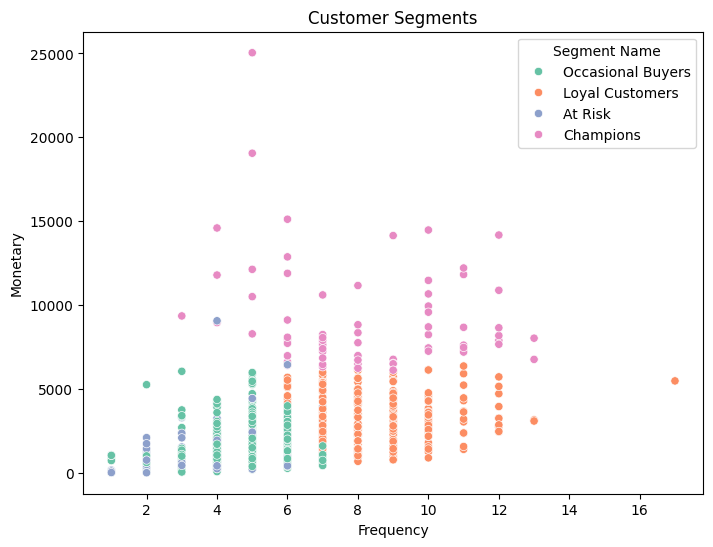

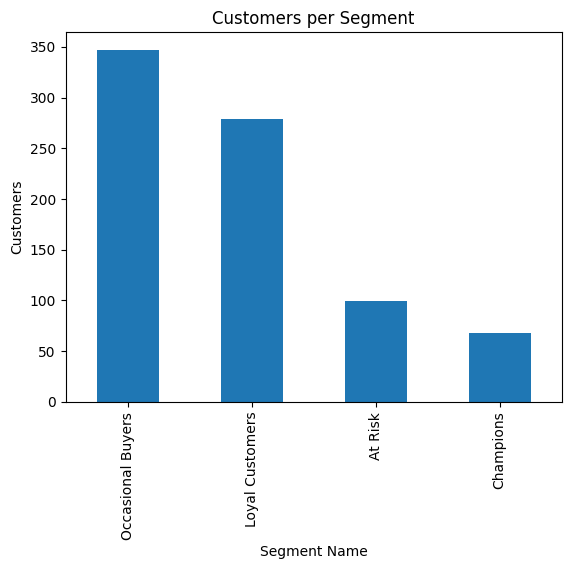

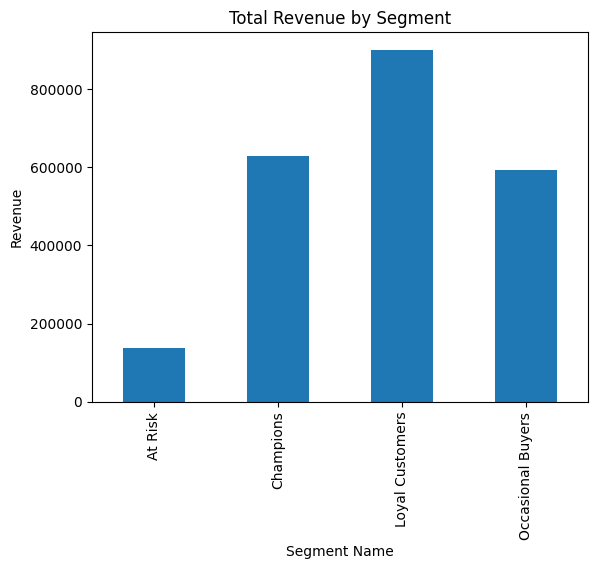

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Segment Name", palette="Set2")
plt.title("Customer Segments")
plt.show()

rfm["Segment Name"].value_counts().plot(kind="bar", title="Customers per Segment")
plt.ylabel("Customers")
plt.show()

rfm.groupby("Segment Name")["Monetary"].sum().plot(kind="bar", title="Total Revenue by Segment")
plt.ylabel("Revenue")
plt.show()

## Key Insights

- 793 customers were grouped into 4 segments using RFM and K-Means (k=4, chosen by the elbow method).
- Loyal Customers (279) generate the most revenue, about 9 lakh in total.
- Champions are only 68 customers (about 9%) yet generate about 6 lakh, roughly the same as the 347 Occasional Buyers.
- At Risk customers (99) have not ordered in about 556 days on average and contribute the least revenue.
- Occasional Buyers are the largest group and the best target for upselling.

## Recommendations

- Reward Champions with a loyalty program and early access to new products.
- Keep Loyal Customers engaged with bundles and regular offers.
- Win back At Risk customers with discount campaigns.
- Encourage Occasional Buyers to order more often with targeted promotions.
